# Graphene on h-BN

After spending some time with the standard layered combinations of graphene, we can now turn our attention to graphene on h-BN. For the purpose of this session, we will be using an [effective model extracted from DFT calculations](https://journals.aps.org/prb/abstract/10.1103/PhysRevB.89.205414) which is accurate close to the K-point. This effective model allows to capture and collapse the effect of h-BN in a moire system by simply modifying the onsite energies and hopping terms in a reference graphene layer. We thus reduce computational cost by a factor 2.

We remind the expression for this Hamiltonian here:
$$
H_\text{eff}(\textbf{r})=H_{0}(\textbf{r})+H_{z}(\textbf{r})+H_{xy}(\textbf{r})
$$
based on the local stacking function $\textbf{d}(\textbf{r}) = (\alpha \mathcal{R}(\theta)-1)\textbf{r}$ where $\alpha = a_G/a_{BN} = 1+\epsilon$ with the lattice constants of graphene (hBN) in the numerator (denominator) and $\mathcal{R}(\theta)$ is the rotation operator acting on an atom at lattice $\textbf{r}$.
The graphene layer Hamiltonian terms acquire the periodic corrections defined as
$$
H_{0}(\textbf{r}) = 2C_0 \Re e[f(\textbf{r})\exp(i\phi_{0})],
$$
$$
H_{z}(\textbf{r}) = 2C_z \Re e[f(\textbf{r})\exp(i\phi_{z})]
$$
with
$$
f(\textbf{r}) = \sum_m \exp(i \textbf{G}_m \cdot \textbf{d}(\textbf{r}))(1+(-1)^m)/2
$$
where $\textbf{G}_m$ are the reciprocal lattice vectors
and 
$$
H_{AB}(\textbf{r}) = H_{xy}^\ast(\textbf{r})
$$
where
$$
H_{xy}(\textbf{r}) = 2 C_{xy} \cos(\phi) (\textbf{z}) \times \nabla \Re e \left[ e^{i\phi_xy} f(\textbf{r})\right]
$$

## Input file and parameters

We include the following flags to add an effective moire model on top of the pristine graphene system.

In [ ]:
fileName = "Gendata.in"
workingDir = rootDir + "GBN/hamiltonian/"
os.makedirs(workingDir, exist_ok=True)
os.chdir(workingDir)

inputStrings_generic = ["Description Generate TB data", # No need to modify
                       "Prefix generate" # No need to modify
                       ]

inputStrings_cell = ["TypeOfSystem Graphene", # To build graphene using the built-in grabnes methods
                       "Supercell 1", # Size of the supercell, i.e. number of repetitions of the unit cell in the x and y direction
                       "CellSize 55" # Number of repetitions of the graphene unit cell, useful when building a larger moire unit cell
                      ]

inputStrings_calc = ["Calculate.OnlyDOS .false.", # Calculate DOS using recursion without time evolution
                            "Kubo.Calc .false.", # Activate Lanczos and possibly Kubo parts of the code
                            "Diag.Calc .false.", # Use exact diagonalization methods from the code
                            "Calculate.Bands .false.", # Electronic band structure calculation
                            "Calculate.DOS .false.", # Electronic band structure calculation
                            "Calculate.spectral .false." # Electronic band structure calculation
                           ]

inputStrings_ham = ["TB.OnSiteC 0.0", # Controls the onsite energy of the carbon atoms, used for the F2G2 model
                    "TB.Hopping 3.03", # Controls the first nearest neighbor hopping in the F2G2 model
                    "MoirePotential .true.", # Activate the effective potential routines
                    "MoireJeil .true.", # Active the effective potential from Jung 2014
                    "MoireOffDiag .true.", # Include the offdiagonal HAB terms from this potential
                    "MoireOnlyH0 .true.", # include only H0
                    "MoireOnlyHZ .false.",
                    "MoireNoH0AndHZ .false.",
                    "MoireH0AndHZ .false.", # Inlcude both H0 and Hz from this potential
                    "MoirePotC0   0-0.01013", # Control the parameters from the effective potential, here values for rigid configuration
                    "MoirePotCz   0-0.00901", #
                    "MoirePotCab   0.01134", #
                    "MoirePotPhi0  1.510233401750693", #
                    "MoirePotPhiz  0.147131255943122", #
                    "MoirePotPhiab  0.342084533390889", #
                    "Latticepercent  0-0.018181818181818",# Control the lattice mismatch taking hBN layer as reference (hence the negative sign). Must be equal to -1/CellSize. Adjust CellSize accordingly for different moire cell sizes.
                    "WriteDataFiles .true.", 
                    "WritePos .true."
]

inputStrings = (inputStrings_generic 
                +inputStrings_cell
                +inputStrings_calc
                +inputStrings_ham
                )

pg.createInputFile(fileName, workingDir, inputStrings)

In [ ]:
os.chdir(workingDir)
!/drive/MyDrive/Twistronics2023/code/grabnes Gendata.in  > out.log

## Hamiltonian visualization

Because the effective model modifies the onsite energies of the graphene layer depending on the local displacement value between a carbon atom and the virtual B and N atoms, we can easily visualize this effect by making a scatter plot which visualizes the energies. To write out the Hamiltonian files (including a few other files), you can use the `WriteDataFiles .true.` flag. Beware to avoid this flag when your system is too large, _i.e._ when you are working on large supercells for the Lanczos calculations. We have already added that flag for convenience in the above input parameter cell.

Text(0.5, 1.0, 'onsite energies from $H_0$')

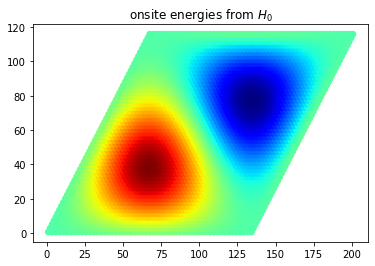

In [ ]:
import importlib
os.chdir(rootDir + "scripts/")
importlib.reload(pg)
os.chdir(workingDir)
pg.plot_onsite_energies("generate.pos", "generate.e")
plt.title(r"onsite energies from $H_0$")

If the calculation ran correctly and as a visual check for possible errors in the implementation, one can compare this real-space representation of $H_0$-induced onsite energies with the corresponding displacement-dependent maps from [this reference](https://journals.aps.org/prb/abstract/10.1103/PhysRevB.89.205414).

## DOS

In [ ]:
fileName = "Gendata.in"
workingDir = rootDir + "GBN/lanczosDOS_5/"
os.makedirs(workingDir, exist_ok=True)
os.chdir(workingDir)

inputStrings_generic = ["Description Generate TB data", # No need to modify
                       "Prefix generate" # No need to modify
                       ]

inputStrings_cell = ["TypeOfSystem Graphene", # To build graphene using the built-in grabnes methods
                       "Supercell 10", # Size of the supercell, i.e. number of repetitions of the unit cell in the x and y direction
                       "CellSize 55" # Number of repetitions of the graphene unit cell, useful when building a larger moire unit cell
                      ]

inputStrings_calc = ["Calculate.OnlyDOS .true.", # Calculate DOS using recursion without time evolution
                            "Kubo.Calc .true.", # Activate Lanczos and possibly Kubo parts of the code
                            "Diag.Calc .false.", # Use exact diagonalization methods from the code
                            "Calculate.Bands .false.", # Electronic band structure calculation
                            "Calculate.DOS .false.", # Electronic band structure calculation
                            "Calculate.spectral .false." # Electronic band structure calculation
                           ]

inputStrings_neigh = ["Neigh.LayerNeighbors 5", # Take large enough value to avoid segmentation fault when building the neighbor lists
                      "TB.NeighLevels 1"] # Set it to 1 for only first nearest neighbor interaction, set it to 5 for F2G2 model
                      #"Neigh.LayerDistFactor 1.2"] # Not importat
                      #"BulkSmall .true.",
                      #"Bulk .true."]

inputStrings_ham = ["TB.OnSiteC 0.0", # Controls the onsite energy of the carbon atoms, used for the F2G2 model
                    "TB.Hopping 3.03", # Controls the first nearest neighbor hopping in the F2G2 model
                    "MoirePotential .true.", # Activate the effective potential routines
                    "MoireJeil .true.", # Active the effective potential from Jung 2014
                    "MoireOffDiag .true.", # Include the offdiagonal HAB terms from this potential
                    "MoireOnlyH0 .false.",
                    "MoireOnlyHZ .false.",
                    "MoireNoH0AndHZ .false.",
                    "MoireH0AndHZ .true.", # Inlcude both H0 and Hz from this potential
                    "MoirePotC0   0-0.01013", # Control the parameters from the effective potential, here values for rigid configuration
                    "MoirePotCz   0-0.00901", #
                    "MoirePotCab   0.01134", #
                    "MoirePotPhi0  1.510233401750693", #
                    "MoirePotPhiz  0.147131255943122", #
                    "MoirePotPhiab  0.342084533390889", #
                    "Latticepercent  0-0.018181818181818" # Control the lattice mismatch taking hBN layer as reference (hence the negative sign). Must be equal to -1/CellSize. Adjust CellSize accordingly for different moire cell sizes.
]

inputStrings_lanczos = ["EnergyMin 0.0-1.0", # Minimum energy for plotting purposes
                        "EnergyMax 1.0", # Maximum energy for plotting purposes
                        "NumberOfRecursion 1000"] # Set the number of recursion steps
inputStrings = (inputStrings_generic 
                +inputStrings_cell
                +inputStrings_calc
                +inputStrings_neigh
                +inputStrings_lanczos
                +inputStrings_ham)

pg.createInputFile(fileName, workingDir, inputStrings)

In [ ]:
os.chdir(workingDir)
!/drive/MyDrive/Twistronics2023/code/grabnes Gendata.in  > out.log


[autoreload of PyToGrabnes failed: Traceback (most recent call last):
  File "/usr/local/lib/python3.8/dist-packages/IPython/extensions/autoreload.py", line 245, in check
    superreload(m, reload, self.old_objects)
  File "/usr/local/lib/python3.8/dist-packages/IPython/extensions/autoreload.py", line 394, in superreload
    module = reload(module)
  File "/usr/lib/python3.8/imp.py", line 314, in reload
    return importlib.reload(module)
  File "/usr/lib/python3.8/importlib/__init__.py", line 168, in reload
    raise ModuleNotFoundError(f"spec not found for the module {name!r}", name=name)
ModuleNotFoundError: spec not found for the module 'PyToGrabnes'
]


(0.0, 0.04)

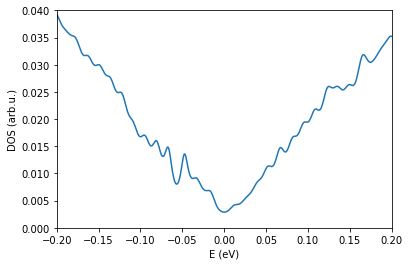

In [ ]:
os.chdir(workingDir)
fileName = "generate.DOS" # update with correct DOS
pg.plotDOS(fileName) # testing the metho
plt.xlim(-0.2,0.2)
plt.ylim(0.0,0.04)

### Magnetic field DOS

#### Zero disorder

In [ ]:
fileName = "Gendata.in"
workingDir = rootDir + "GBN/lanczosDOS_5/"
os.makedirs(workingDir, exist_ok=True)
os.chdir(workingDir)

inputStrings_generic = ["Description Generate TB data", # No need to modify
                       "Prefix generate" # No need to modify
                       ]

inputStrings_cell = ["TypeOfSystem Graphene", # To build graphene using the built-in grabnes methods
                       "Supercell 10", # Size of the supercell, i.e. number of repetitions of the unit cell in the x and y direction
                       "CellSize 55" # Number of repetitions of the graphene unit cell, useful when building a larger moire unit cell
                      ]

inputStrings_calc = ["Calculate.OnlyDOS .true.", # Calculate DOS using recursion without time evolution
                            "Kubo.Calc .true.", # Activate Lanczos and possibly Kubo parts of the code
                            "Diag.Calc .false.", # Use exact diagonalization methods from the code
                            "Calculate.Bands .false.", # Electronic band structure calculation
                            "Calculate.DOS .false.", # Electronic band structure calculation
                            "Calculate.spectral .false." # Electronic band structure calculation
                           ]

inputStrings_neigh = ["Neigh.LayerNeighbors 5", # Take large enough value to avoid segmentation fault when building the neighbor lists
                      "TB.NeighLevels 1"] # Set it to 1 for only first nearest neighbor interaction, set it to 5 for F2G2 model
                      #"Neigh.LayerDistFactor 1.2"] # Not importat
                      #"BulkSmall .true.",
                      #"Bulk .true."]

inputStrings_ham = ["TB.OnSiteC 0.0", # Controls the onsite energy of the carbon atoms, used for the F2G2 model
                    "TB.Hopping 3.03", # Controls the first nearest neighbor hopping in the F2G2 model
                    "MoirePotential .true.", # Activate the effective potential routines
                    "MoireJeil .true.", # Active the effective potential from Jung 2014
                    "MoireOffDiag .true.", # Include the offdiagonal HAB terms from this potential
                    "MoireOnlyH0 .false.",
                    "MoireOnlyHZ .false.",
                    "MoireNoH0AndHZ .false.",
                    "MoireH0AndHZ .true.", # Inlcude both H0 and Hz from this potential
                    "MoirePotC0   0-0.01013", # Control the parameters from the effective potential, here values for rigid configuration
                    "MoirePotCz   0-0.00901", #
                    "MoirePotCab   0.01134", #
                    "MoirePotPhi0  1.510233401750693", #
                    "MoirePotPhiz  0.147131255943122", #
                    "MoirePotPhiab  0.342084533390889", #
                    "Latticepercent  0-0.018181818181818" # Control the lattice mismatch taking hBN layer as reference (hence the negative sign). Must be equal to -1/CellSize. Adjust CellSize accordingly for different moire cell sizes.
                    ]

inputStrings_lanczos = ["EnergyMin 0.0-1.0", # Minimum energy for plotting purposes
                        "EnergyMax 1.0", # Maximum energy for plotting purposes
                        "NumberOfRecursion 1000"] # Set the number of recursion steps

inputStrings_mag = ["MagField.Integer 100" # Specify the integer that controls the magnetic field based on the simulation cell size.
                   # "MagField 50" # Specify the magnetic field in Tesla
                   # "MagField.InitialInteger 0 # Use this if you want to repeat the calculation for several magnetic fields. Useful for the calculation of Hofstadter butterfly diagrams or Wannier diagrams.
                   # "MagField.FinalInteger 1000
                   # "MagField.IntegerStep 2
                    ]

inputStrings = (inputStrings_generic 
                +inputStrings_cell
                +inputStrings_calc
                +inputStrings_neigh
                +inputStrings_lanczos
                +inputStrings_ham
                +inputStrings_mag)

pg.createInputFile(fileName, workingDir, inputStrings)

In [ ]:
os.chdir(workingDir)
!/drive/MyDrive/Twistronics2023/code/grabnes Gendata.in  > out.log

(0.0, 0.08)

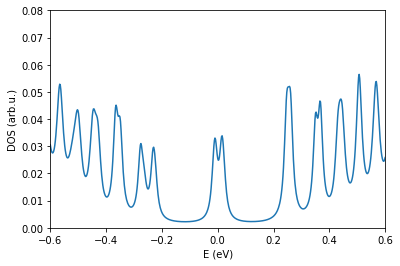

In [ ]:
os.chdir(workingDir)
fileName = "generate.DOS" # update with correct DOS
pg.plotDOS(fileName) # testing the metho
plt.xlim(-0.6,0.6)
plt.ylim(0.0,0.08)

#### Anderson disorder

To illustrate the modular nature of the code when building the Hamiltonian, we illustrate here what happens when adding Anderson disorder on top of the current G-hBN effective model Hamiltonian in presence of a magnetic field.

In [ ]:
fileName = "Gendata.in"
workingDir = rootDir + "GBN/lanczosDOS_5/"
os.makedirs(workingDir, exist_ok=True)
os.chdir(workingDir)

inputStrings_generic = ["Description Generate TB data", # No need to modify
                       "Prefix generate" # No need to modify
                       ]

inputStrings_cell = ["TypeOfSystem Graphene", # To build graphene using the built-in grabnes methods
                       "Supercell 10", # Size of the supercell, i.e. number of repetitions of the unit cell in the x and y direction
                       "CellSize 55" # Number of repetitions of the graphene unit cell, useful when building a larger moire unit cell
                      ]

inputStrings_calc = ["Calculate.OnlyDOS .true.", # Calculate DOS using recursion without time evolution
                            "Kubo.Calc .true.", # Activate Lanczos and possibly Kubo parts of the code
                            "Diag.Calc .false.", # Use exact diagonalization methods from the code
                            "Calculate.Bands .false.", # Electronic band structure calculation
                            "Calculate.DOS .false.", # Electronic band structure calculation
                            "Calculate.spectral .false." # Electronic band structure calculation
                           ]

inputStrings_neigh = ["Neigh.LayerNeighbors 5", # Take large enough value to avoid segmentation fault when building the neighbor lists
                      "TB.NeighLevels 1"] # Set it to 1 for only first nearest neighbor interaction, set it to 5 for F2G2 model
                      #"Neigh.LayerDistFactor 1.2"] # Not importat
                      #"BulkSmall .true.",
                      #"Bulk .true."]

inputStrings_ham = ["TB.OnSiteC 0.0", # Controls the onsite energy of the carbon atoms, used for the F2G2 model
                    "TB.Hopping 3.03", # Controls the first nearest neighbor hopping in the F2G2 model
                    "MoirePotential .true.", # Activate the effective potential routines
                    "MoireJeil .true.", # Active the effective potential from Jung 2014
                    "MoireOffDiag .true.", # Include the offdiagonal HAB terms from this potential
                    "MoireOnlyH0 .false.",
                    "MoireOnlyHZ .false.",
                    "MoireNoH0AndHZ .false.",
                    "MoireH0AndHZ .true.", # Inlcude both H0 and Hz from this potential
                    "MoirePotC0   0-0.01013", # Control the parameters from the effective potential, here values for rigid configuration
                    "MoirePotCz   0-0.00901", #
                    "MoirePotCab   0.01134", #
                    "MoirePotPhi0  1.510233401750693", #
                    "MoirePotPhiz  0.147131255943122", #
                    "MoirePotPhiab  0.342084533390889", #
                    "Latticepercent  0-0.018181818181818" # Control the lattice mismatch taking hBN layer as reference (hence the negative sign). Must be equal to -1/CellSize. Adjust CellSize accordingly for different moire cell sizes.
                    ]

inputStrings_lanczos = ["EnergyMin 0.0-1.0", # Minimum energy for plotting purposes
                        "EnergyMax 1.0", # Maximum energy for plotting purposes
                        "NumberOfRecursion 1000"] # Set the number of recursion steps

inputStrings_mag = ["MagField.Integer 100" # Specify the integer that controls the magnetic field based on the simulation cell size.
                   # "MagField 50" # Specify the magnetic field in Tesla
                   # "MagField.InitialInteger 0 # Use this if you want to repeat the calculation for several magnetic fields. Useful for the calculation of Hofstadter butterfly diagrams or Wannier diagrams.
                   # "MagField.FinalInteger 1000
                   # "MagField.IntegerStep 2
                    ]

inputStrings_disorder = ["Anderson .true.",
                         "AndersonAmp 1.0",
                         ]

inputStrings = (inputStrings_generic 
                +inputStrings_cell
                +inputStrings_calc
                +inputStrings_neigh
                +inputStrings_lanczos
                +inputStrings_ham
                +inputStrings_mag
                +inputStrings_disorder)

pg.createInputFile(fileName, workingDir, inputStrings)

In [ ]:
os.chdir(workingDir)
!/drive/MyDrive/Twistronics2023/code/grabnes Gendata.in  > out.log

(0.0, 0.08)

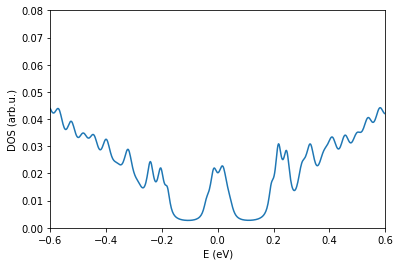

In [ ]:
os.chdir(workingDir)
fileName = "generate.DOS" # update with correct DOS
pg.plotDOS(fileName) # testing the metho
plt.xlim(-0.6,0.6)
plt.ylim(0.0,0.08)

If you correctly ran the code, the Landau levels become wider due to the presence of more localized disorder states in the tails around the center of the Landau level where the extended states reside. If you increase the disorder even further, the Landau levels cannot form anymore and a regular Anderson disorder insulator develops at all energies where all the states are localized.

# Future work

In case you would like to explore the capabilities of this code further (including transport observables, band-unfolding methods, etC), feel free to come talk to as well as check out the GRABNES documentation for further reference. This documentation is a work in progress, so for specific questions, let's have a chat or shoot me an email (lecontenicolas@gmail.com).